<a href="https://colab.research.google.com/github/maulidyaafriani/Pembelajaran-Mesin-2026/blob/main/TG13_ANN_JST_244107020059_MAULIDYA_AFRIANI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama: Maulidya AFriani

NIM: 244107020059

Kelas: TI-3G


# Praktikum ANN - Artificial Neural Network (Praktikum 1 – Tugas Praktikum)


# Praktikum 1 — ANN Sederhana (XOR), Backpropagation Manual

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.30184582188716846
Epoch 1000, Loss: 0.22434176359233768
Epoch 2000, Loss: 0.11886755167946692
Epoch 3000, Loss: 0.039305702777675526
Epoch 4000, Loss: 0.019281762069994865
Epoch 5000, Loss: 0.012084325541520061
Epoch 6000, Loss: 0.008608242452731795
Epoch 7000, Loss: 0.00661266777015838
Epoch 8000, Loss: 0.005334827552789186
Epoch 9000, Loss: 0.00445337719916906
Prediksi:
[[0.05982177]
 [0.93332044]
 [0.93394653]
 [0.05349458]]


## Tugas 1
- Ubah jumlah neuron hidden layer menjadi 3
- Bandingkan loss dengan konfigurasi awal
- Tambahkan aktivasi ReLU dan bandingkan

Kode training dibungkus dalam fungsi `train_xor(hidden_size, activation, seed)`. Pada ReLU, turunan dihitung dari `z1` (`z1 > 0`), sedangkan pada sigmoid dari output aktivasi. Output layer tetap sigmoid.
Karena XOR sangat sensitif terhadap inisialisasi bobot, tiap konfigurasi dijalankan dengan **30 seed berbeda** (seed sama untuk semua konfigurasi agar adil).

In [2]:
def relu(x): return np.maximum(0, x)

def train_xor(hidden_size=2, activation='sigmoid', seed=0, epochs=10000, lr=0.1):
    rng = np.random.RandomState(seed)
    W1 = rng.randn(2, hidden_size); b1 = np.zeros((1, hidden_size))
    W2 = rng.randn(hidden_size, 1); b2 = np.zeros((1, 1))
    history = []
    for epoch in range(epochs):
        z1 = X @ W1 + b1
        a1 = sigmoid(z1) if activation == 'sigmoid' else relu(z1)
        a2 = sigmoid(a1 @ W2 + b2)
        error = y - a2

        d_a2 = error * a2 * (1 - a2)
        d_W2 = a1.T @ d_a2
        d_b2 = d_a2.sum(axis=0, keepdims=True)
        d_hidden = (a1 * (1 - a1)) if activation == 'sigmoid' else (z1 > 0).astype(float)
        d_a1 = (d_a2 @ W2.T) * d_hidden
        d_W1 = X.T @ d_a1
        d_b1 = d_a1.sum(axis=0, keepdims=True)

        W1 += lr * d_W1; b1 += lr * d_b1
        W2 += lr * d_W2; b2 += lr * d_b2
        history.append(np.mean(error ** 2))
    return history, a2

configs = [(2, 'sigmoid'), (3, 'sigmoid'), (2, 'relu'), (3, 'relu')]
rows, curves = [], {}
for h, act in configs:
    finals, benar = [], 0
    for s in range(30):
        hist, pred = train_xor(h, act, seed=s)
        finals.append(hist[-1])
        benar += int(((pred > 0.5) == y).all())
        if s == 0: curves[(h, act)] = hist
    rows.append({'Hidden': h, 'Aktivasi hidden': act,
                 'Loss akhir (rata-rata 30 seed)': round(np.mean(finals), 5),
                 'Loss akhir (median)': round(np.median(finals), 5),
                 'Seed berhasil (XOR benar semua)': f'{benar}/30'})
hasil_xor = pd.DataFrame(rows)
hasil_xor

,Hidden,Aktivasi hidden,Loss akhir (rata-rata 30 seed),Loss akhir (median),Seed berhasil (XOR benar semua)
0,2,sigmoid,0.03239,0.00301,23/30
1,3,sigmoid,0.00265,0.00233,30/30
2,2,relu,0.15285,0.16669,5/30
3,3,relu,0.08211,0.00036,16/30


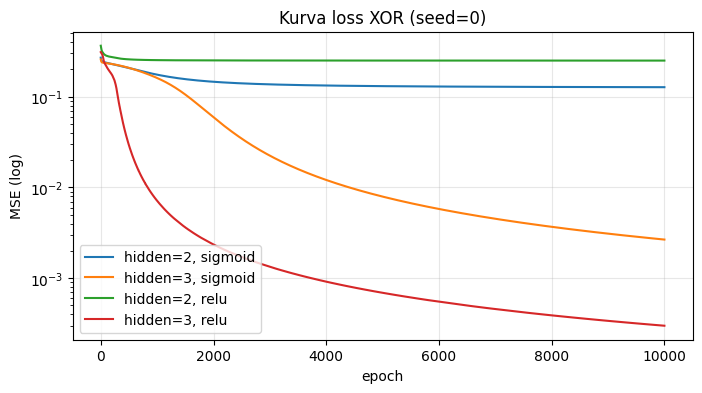

In [3]:
plt.figure(figsize=(8, 4))
for (h, act), hist in curves.items():
    plt.plot(hist, label=f'hidden={h}, {act}')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE (log)'); plt.title('Kurva loss XOR (seed=0)')
plt.legend(); plt.grid(alpha=.3); plt.show()

**Analisis:**
- Hidden 3 biasanya lebih stabil konvergen daripada hidden 2 karena kapasitas lebih besar (hidden 2 lebih sering terjebak local minimum).
- ReLU pada jaringan sekecil ini cenderung kurang stabil (risiko *dead neuron*, dan lr=0.1 tanpa normalisasi) dibanding sigmoid. Tulis kesimpulan sesuai tabel hasil run-mu.

# Praktikum 2 — Klasifikasi Iris dengan Keras

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=8)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3333 - loss: 2.0553
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3333 - loss: 1.5227 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3333 - loss: 1.1957 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3750 - loss: 0.9941 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6250 - loss: 0.8538 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5417 - loss: 0.7552 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6083 - loss: 0.6729 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6583 - loss: 0.6101 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7083 - loss: 0.5729 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6833 - loss: 0.5446 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6833 - loss: 0.5198 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0

## Tugas 2 — Ubah jumlah neuron hidden layer & bandingkan akurasi
Split dibuat tetap (`random_state=42`, stratified) dan seed TensorFlow di-set supaya perbandingan adil. Konfigurasi awal (10, 8) dimasukkan sebagai pembanding.

In [5]:
import time
Xtr, Xte, ytr, yte = train_test_split(iris.data, y, test_size=0.2, random_state=42, stratify=iris.target)

def build_iris(hidden=(10, 8), activation='relu'):
    layers = [tf.keras.Input(shape=(4,))]
    layers += [tf.keras.layers.Dense(n, activation=activation) for n in hidden]
    layers += [tf.keras.layers.Dense(3, activation='softmax')]
    m = tf.keras.Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def run_iris(hidden, activation='relu', seeds=(0, 1, 2, 3, 4)):
    accs, losses = [], []
    for s in seeds:
        tf.keras.utils.set_random_seed(s)
        m = build_iris(hidden, activation)
        m.fit(Xtr, ytr, epochs=50, batch_size=8, verbose=0)
        l, a = m.evaluate(Xte, yte, verbose=0)
        accs.append(a); losses.append(l)
    return np.mean(losses), np.mean(accs), np.std(accs)

rows = []
for hidden in [(10, 8), (4, 4), (32, 16), (64, 32), (128, 64)]:
    l, a, sd = run_iris(hidden)
    rows.append({'Hidden layer': str(hidden), 'Loss test': round(l, 4),
                 'Akurasi test (rata-rata 5 seed)': round(a, 4), 'Std': round(sd, 4)})
hasil_tugas2 = pd.DataFrame(rows)
hasil_tugas2

,Hidden layer,Loss test,Akurasi test (rata-rata 5 seed),Std
0,"(10, 8)",0.3209,0.9400,0.0533
1,"(4, 4)",0.7752,0.6333,0.1738
2,"(32, 16)",0.1308,0.9933,0.0133
3,"(64, 32)",0.0808,1.0000,0.0000
4,"(128, 64)",0.0603,1.0000,0.0000


## Tugas 3 — Sigmoid vs ReLU pada Iris

In [6]:
rows = []
for act in ['relu', 'sigmoid']:
    l, a, sd = run_iris((10, 8), activation=act)
    rows.append({'Aktivasi hidden': act, 'Loss test': round(l, 4),
                 'Akurasi test (rata-rata 5 seed)': round(a, 4), 'Std': round(sd, 4)})
hasil_tugas3 = pd.DataFrame(rows)
hasil_tugas3

,Aktivasi hidden,Loss test,Akurasi test (rata-rata 5 seed),Std
0,relu,0.3209,0.94,0.0533
1,sigmoid,0.5799,0.82,0.0400


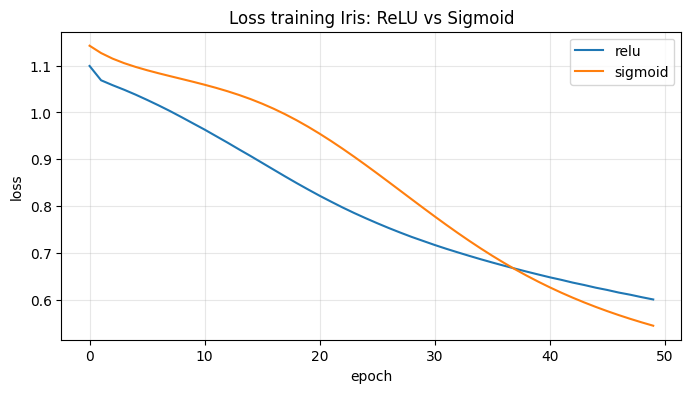

In [7]:
# Kurva loss training untuk perbandingan visual
plt.figure(figsize=(8, 4))
for act in ['relu', 'sigmoid']:
    tf.keras.utils.set_random_seed(0)
    m = build_iris((10, 8), act)
    h = m.fit(Xtr, ytr, epochs=50, batch_size=8, verbose=0)
    plt.plot(h.history['loss'], label=act)
plt.xlabel('epoch'); plt.ylabel('loss'); plt.title('Loss training Iris: ReLU vs Sigmoid')
plt.legend(); plt.grid(alpha=.3); plt.show()

# Praktikum 3 — Regresi Harga Rumah dengan Keras

In [8]:
from sklearn.preprocessing import StandardScaler

# Contoh dataset (dummy)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi (scaler dipisah untuk X dan y)
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi (prediksi dikembalikan ke skala harga asli)
pred = scaler_y.inverse_transform(model.predict(X_test))
print("Prediksi:", pred.ravel())
print("Aktual  :", scaler_y.inverse_transform(y_test).ravel())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Prediksi: [633.0245]
Aktual  : [600.]


## Tugas 4 — Ubah learning rate & bandingkan loss
Data dummy 5 baris terlalu kecil untuk perbandingan yang bermakna, sehingga dibuat dummy yang lebih besar (harga = 10 × luas + noise). Hasil loss dibandingkan pada **data validasi**.

In [9]:
rng = np.random.RandomState(0)
luas = rng.uniform(30, 200, 300)
harga = 10 * luas + rng.normal(0, 50, 300)

sx, sy = StandardScaler(), StandardScaler()
Xd = sx.fit_transform(luas.reshape(-1, 1))
yd = sy.fit_transform(harga.reshape(-1, 1))
Xd_tr, Xd_va, yd_tr, yd_va = train_test_split(Xd, yd, test_size=0.2, random_state=42)

def run_lr(lr, epochs=100):
    tf.keras.utils.set_random_seed(0)
    m = tf.keras.Sequential([tf.keras.Input(shape=(1,)),
                             tf.keras.layers.Dense(10, activation='relu'),
                             tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    return m.fit(Xd_tr, yd_tr, validation_data=(Xd_va, yd_va), epochs=epochs, verbose=0)

lrs = [0.1, 0.01, 0.001, 0.0001]
hist_lr = {lr: run_lr(lr) for lr in lrs}

hasil_tugas4 = pd.DataFrame([{
    'Learning rate': lr,
    'Train loss akhir': round(h.history['loss'][-1], 4),
    'Val loss akhir': round(h.history['val_loss'][-1], 4)} for lr, h in hist_lr.items()])
hasil_tugas4

,Learning rate,Train loss akhir,Val loss akhir
0,0.1000,0.0133,0.0212
1,0.0100,0.0098,0.0124
2,0.0010,0.0180,0.0195
3,0.0001,0.7564,0.6475


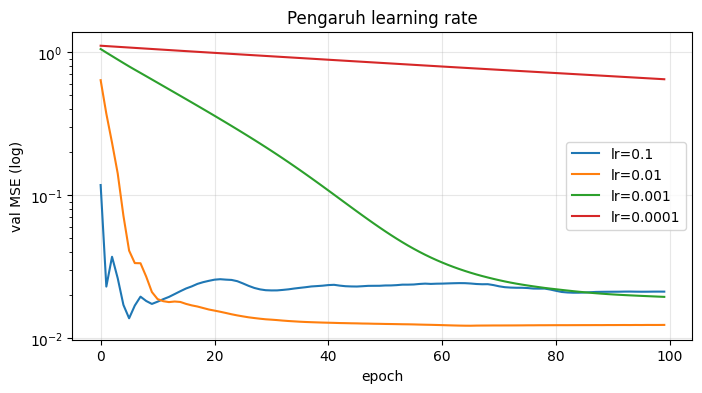

In [10]:
plt.figure(figsize=(8, 4))
for lr, h in hist_lr.items():
    plt.plot(h.history['val_loss'], label=f'lr={lr}')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('val MSE (log)')
plt.title('Pengaruh learning rate'); plt.legend(); plt.grid(alpha=.3); plt.show()

**Analisis:** lr terlalu kecil (0.0001) → belum konvergen dalam 100 epoch; lr sedang (0.001–0.01) biasanya paling baik; lr besar (0.1) bisa cepat tapi kurang stabil. Sesuaikan dengan hasilmu.

## MLP Regresi — Data Boston (harga rumah)

In [11]:
# load_boston sudah dihapus dari scikit-learn terbaru -> pakai fetch_openml
try:
    from sklearn.datasets import fetch_openml
    boston = fetch_openml(name='boston', version=1, as_frame=False, parser='auto')
    X = boston.data.astype(float); y = boston.target.astype(float)
    print('Dataset: Boston Housing', X.shape)
except Exception as e:
    print('Boston tidak bisa diunduh (', e, ') -> pakai California Housing')
    from sklearn.datasets import fetch_california_housing
    ch = fetch_california_housing()
    X, y = ch.data, ch.target
    print('Dataset: California Housing', X.shape)

Dataset: Boston Housing (506, 13)


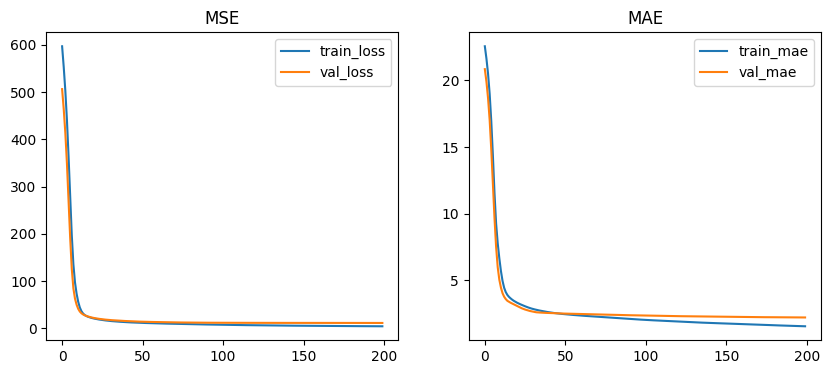

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
RMSE: 3.3639388359314615


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1, 2, 2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

# Tugas Praktikum — Klasifikasi MNIST dengan ANN
Bagian kosong pada template jobsheet (Flatten, 2 hidden layer, output, compile, fit) sudah dilengkapi.

In [13]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 -> 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model ANN
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                        # ubah gambar 28x28 menjadi vektor 784
    Dense(128, activation='relu'),    # hidden layer 1
    Dense(64, activation='relu'),     # hidden layer 2
    Dense(10, activation='softmax')   # output layer (10 kelas)
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
model.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1)

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8980 - loss: 0.3549 - val_accuracy: 0.9587 - val_loss: 0.1478
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9573 - loss: 0.1504 - val_accuracy: 0.9690 - val_loss: 0.1134
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9697 - loss: 0.1046 - val_accuracy: 0.9725 - val_loss: 0.0927
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9775 - loss: 0.0785 - val_accuracy: 0.9743 - val_loss: 0.0826
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9827 - loss: 0.0606 - val_accuracy: 0.9750 - val_loss: 0.0788
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9869 - loss: 0.0474 - val_accuracy: 0.9762 - val_loss: 0.0787
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9899 - loss: 0.0369 - val_accuracy: 0.9758 - val_loss: 0.0817
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step -

## Eksperimen
- Ubah neuron (256, 128)
- Tambah satu hidden layer lagi
- Bandingkan akurasi & waktu pelatihan
- Sigmoid vs ReLU

In [14]:
import time

def build_mnist(hidden, activation='relu'):
    layers = [Input(shape=(28, 28)), Flatten()]
    layers += [Dense(n, activation=activation) for n in hidden]
    layers += [Dense(10, activation='softmax')]
    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

eksperimen = [
    ('A: (128, 64) ReLU - dasar',          (128, 64),       'relu'),
    ('B: (256, 128) ReLU',                 (256, 128),      'relu'),
    ('C: (256, 128, 64) ReLU - 3 hidden',  (256, 128, 64),  'relu'),
    ('D: (128, 64) Sigmoid',               (128, 64),       'sigmoid'),
    ('E: (256, 128) Sigmoid',              (256, 128),      'sigmoid'),
    ('F: (256, 128, 64) Sigmoid',          (256, 128, 64),  'sigmoid'),
]

rows = []
for nama, hidden, act in eksperimen:
    tf.keras.utils.set_random_seed(42)
    m = build_mnist(hidden, act)
    t0 = time.time()
    m.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
    durasi = time.time() - t0
    l, a = m.evaluate(X_test, y_test, verbose=0)
    rows.append({'Model': nama, 'Parameter': m.count_params(),
                 'Loss test': round(l, 4), 'Akurasi test': round(a, 4),
                 'Waktu latih (detik)': round(durasi, 1)})

hasil_mnist = pd.DataFrame(rows)
hasil_mnist

,Model,Parameter,Loss test,Akurasi test,Waktu latih (detik)
0,"A: (128, 64) ReLU - dasar",109386,0.1036,0.9707,39.4
1,"B: (256, 128) ReLU",235146,0.1030,0.9740,46.1
2,"C: (256, 128, 64) ReLU - 3 hidden",242762,0.1101,0.9706,41.4
3,"D: (128, 64) Sigmoid",109386,0.0941,0.9698,28.9
4,"E: (256, 128) Sigmoid",235146,0.0819,0.9738,42.9
5,"F: (256, 128, 64) Sigmoid",242762,0.0939,0.9711,41.9


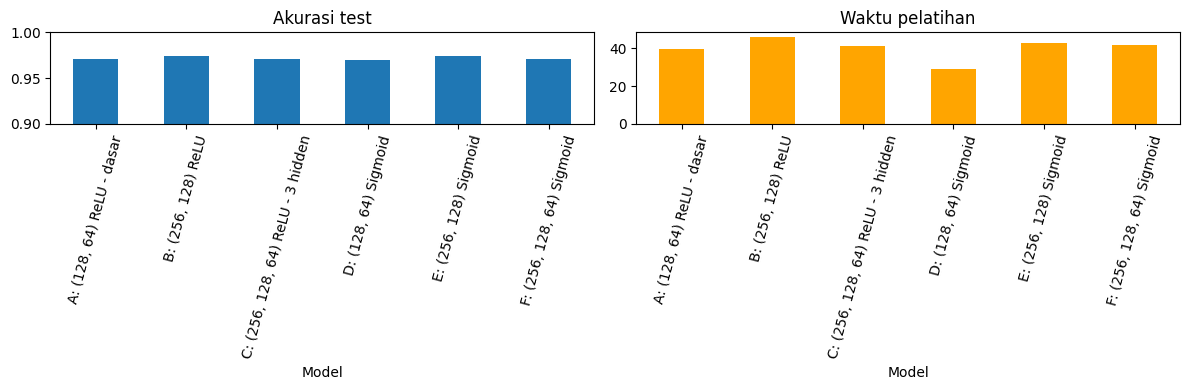

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hasil_mnist.plot(x='Model', y='Akurasi test', kind='bar', ax=ax[0], legend=False, ylim=(0.9, 1.0))
ax[0].set_title('Akurasi test'); ax[0].tick_params(axis='x', rotation=75)
hasil_mnist.plot(x='Model', y='Waktu latih (detik)', kind='bar', ax=ax[1], legend=False, color='orange')
ax[1].set_title('Waktu pelatihan'); ax[1].tick_params(axis='x', rotation=75)
plt.tight_layout(); plt.show()